In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [63]:
# 1. Create 100 sample records
np.random.seed(42) # So we get the same results

data={'WellPad': np.random.choice(['Til-01', 'Til-02', 'Til-03'], 100), 'Well_Type': np.random.choice(['PW', 'WI'], 100),'Mud_Type': np.random.choice(['HPWBM', 'NABM'], 100), 'Depth_m': np.random.randint(500, 3000, 100), 'Mud_Density_ppg': np.round(np.random.uniform(9.0, 12.5, 100), 2), 'Plastic_Viscosity_lb/ft3': np.round(np.random.uniform(15, 25, 100), 1), 'Yield_Point_cP': np.round(np.random.uniform(11, 12, 100), 1), 'Sand_content_%': np.round(np.random.uniform(0.1, 3.5, 100), 2), 'FluidLoss_mL': np.round(np.random.uniform(1.0, 4.0, 100), 2), 'BottomHoleTemperature_C': np.round(np.random.uniform(50, 60, 100), 1), 'BottomHolePressure_psi': np.round(np.random.uniform(50, 60, 100), 1),'PumpStockRate_stk/min': np.round(np.random.uniform(90, 100, 100), 1),'PumpFlowRate_L/min': np.round(np.random.uniform(1500, 1750, 100), 1), 'ECD_ppg': np.round(np.random.normal(0.7, 11.1, 100), 2), 'WellCost_USD': np.round(np.random.uniform(5000, 7000, 100), 1)}
df=pd.DataFrame(data)
df.head(21) # Show first 21 rows


,WellPad,Well_Type,Mud_Type,Depth_m,Mud_Density_ppg,Plastic_Viscosity_lb/ft3,Yield_Point_cP,Sand_content_%,FluidLoss_mL,BottomHoleTemperature_C,BottomHolePressure_psi,PumpStockRate_stk/min,PumpFlowRate_L/min,ECD_ppg,WellCost_USD
0,Til-03,WI,NABM,2950,10.03,20.0,11.8,1.87,1.26,51.2,50.7,96.0,1718.7,9.81,5652.9
1,Til-01,WI,HPWBM,1869,10.35,23.6,11.6,3.00,2.61,59.4,57.5,96.7,1632.2,6.33,6035.4
2,Til-03,WI,HPWBM,2486,11.98,21.6,11.4,1.98,2.76,56.3,52.1,91.8,1734.8,12.54,5175.7
3,Til-03,PW,NABM,2034,10.11,16.6,11.9,2.01,3.24,53.3,59.0,99.1,1699.7,13.68,5701.3
4,Til-01,PW,HPWBM,646,9.59,15.7,11.1,3.08,2.29,51.4,52.1,94.2,1749.5,16.04,5066.4
5,Til-01,PW,HPWBM,2234,10.95,21.4,11.5,1.47,1.38,57.9,51.9,93.8,1587.7,7.90,5157.2
6,Til-03,PW,HPWBM,2343,12.28,15.3,11.0,0.56,1.85,56.2,50.4,95.2,1691.8,-1.16,5793.8
7,Til-02,WI,HPWBM,988,11.44,20.9,11.5,0.20,2.09,55.3,54.7,90.5,1600.5,2.33,5265.4
8,Til-03,PW,NABM,2459,11.00,24.4,11.1,2.67,2.94,58.9,55.6,91.7,1620.0,14.09,6135.1
9,Til-03,PW,HPWBM,2163,9.34,20.8,11.1,2.21,2.71,57.9,50.7,97.4,1656.9,-8.37,6378.9


In [34]:
# 2. Create Average values by Well
print(df.groupby('WellPad').mean(numeric_only=True).round(3))

          Depth_m  Mud_Density_ppg  Plastic_Viscosity_lb/ft3  Yield_Point_cP  \
WellPad                                                                        
Til-01   1645.030           10.461                    20.148          11.509   
Til-02   1768.083           10.748                    20.261          11.653   
Til-03   1954.613           10.927                    20.042          11.523   

         Sand_content_%  FluidLoss_mL  BottomHoleTemperature_C  \
WellPad                                                          
Til-01            1.715         2.475                   54.312   
Til-02            1.426         2.296                   55.258   
Til-03            1.647         2.576                   55.965   

         BottomHolePressure_psi  PumpStockRate_stk/min  PumpFlowRate_L/min  \
WellPad                                                                      
Til-01                   54.318                 94.839            1648.373   
Til-02                   54.150   

In [42]:
# 3. Filter data

print("BottomHoleTemperature_C:", df[df['BottomHoleTemperature_C'] > 56])

BottomHoleTemperature_C:    WellPad Well_Type Mud_Type  Depth_m  Mud_Density_ppg  \
1   Til-01        WI    HPWBM     1869            10.35   
2   Til-03        WI    HPWBM     2486            11.98   
5   Til-01        PW    HPWBM     2234            10.95   
6   Til-03        PW    HPWBM     2343            12.28   
8   Til-03        PW     NABM     2459            11.00   
9   Til-03        PW    HPWBM     2163             9.34   
13  Til-03        WI    HPWBM     2469            10.81   
16  Til-02        PW     NABM     2134            11.44   
17  Til-02        WI    HPWBM      762            11.46   
19  Til-02        PW     NABM     2691            10.03   
21  Til-01        WI    HPWBM     1123            11.84   
24  Til-01        WI     NABM     2549            10.79   
27  Til-03        WI    HPWBM      952            11.27   
28  Til-03        WI     NABM     1683            11.46   
29  Til-03        PW     NABM     2556            11.79   
30  Til-02        PW     NABM  

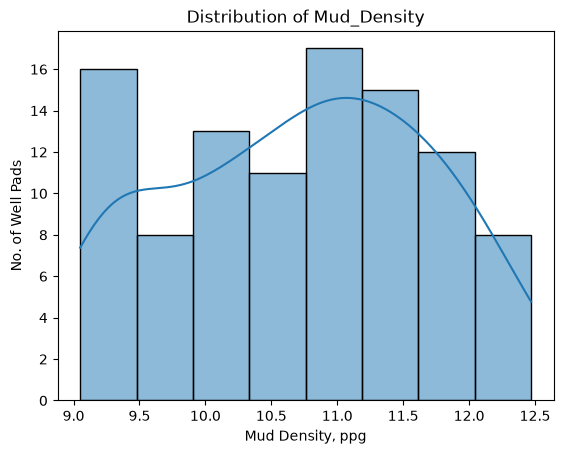

In [46]:
#4. Plot Distribution of Mud Density acrosee the Well Pads

sns.histplot(df['Mud_Density_ppg'], kde=True)
plt.title('Distribution of Mud_Density')
plt.xlabel('Mud Density, ppg')
plt.ylabel('No. of Well Pads')
plt.show()

Text(0.5, 1.0, 'Mud Density Vs Plastic Viscosity')

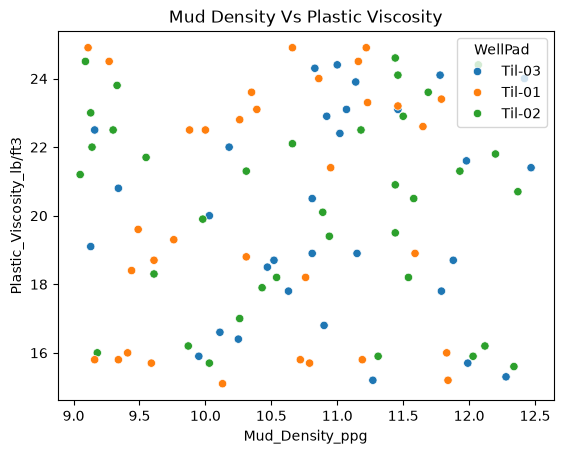

In [47]:
# 5 Scatterplot (Mud density Vs Plastic Viscosity)

sns.scatterplot(data=df, x='Mud_Density_ppg', y='Plastic_Viscosity_lb/ft3', hue='WellPad')
plt.title('Mud Density Vs Plastic Viscosity')


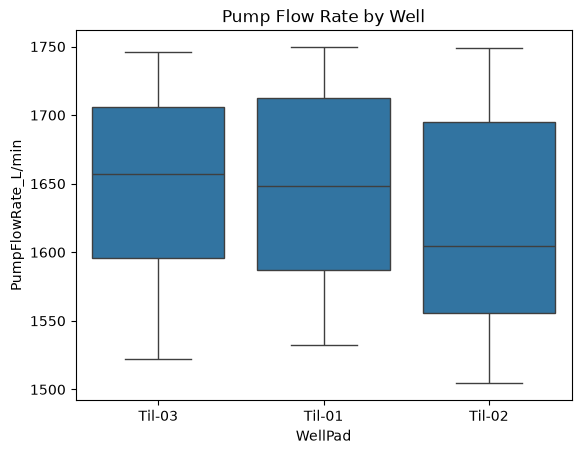

In [49]:
# 6. Box plot diagram of (Pump Flow rate in each Well Pad)

sns.boxplot(data=df, x='WellPad', y='PumpFlowRate_L/min')
plt.title('Pump Flow Rate by Well')
plt.show()

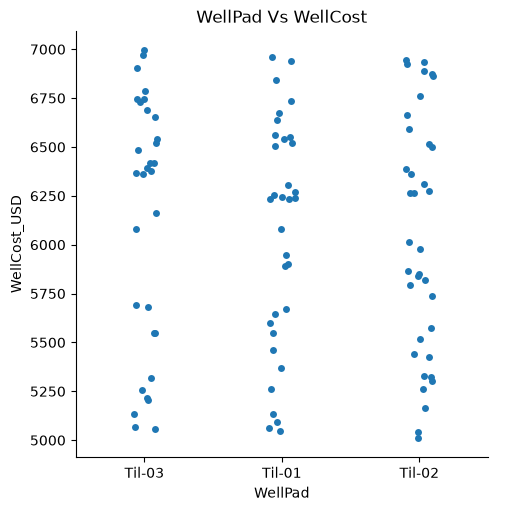

In [53]:
# 7. Categorical plots to display Well cost per Well Pad

sns.catplot(data=df, x='WellPad', y='WellCost_USD')
plt.title('WellPad Vs WellCost')
plt.show()

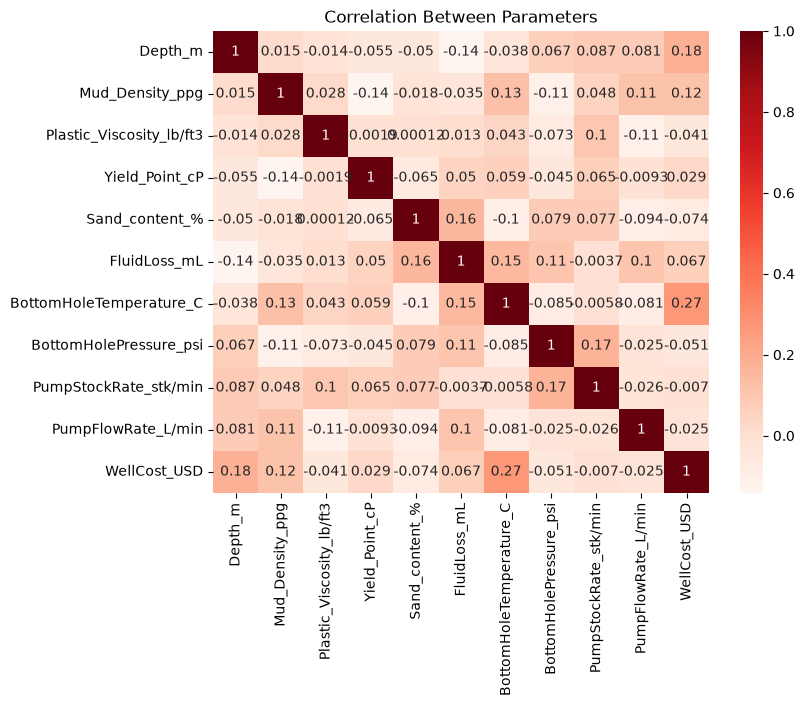

In [60]:
# 8. Correlation between the parameters

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Reds')
plt.title('Correlation Between Parameters')
plt.show()

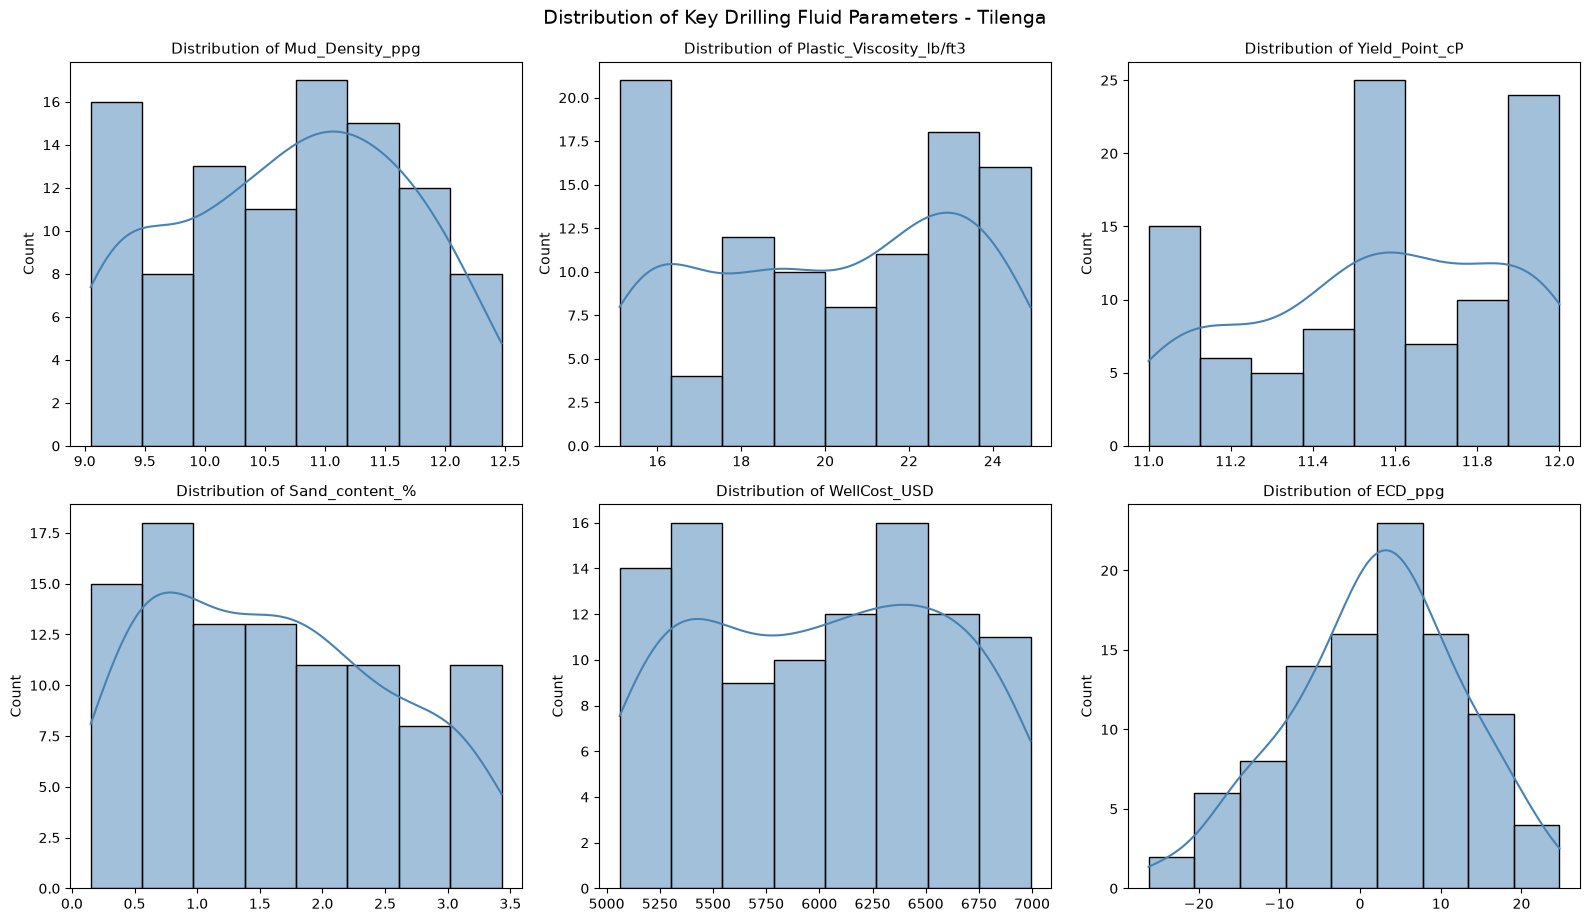

In [72]:
# 9. Distribution of key parameters

key_params = ['Mud_Density_ppg', 'Plastic_Viscosity_lb/ft3', 'Yield_Point_cP',
              'Sand_content_%', 'WellCost_USD', 'ECD_ppg']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(key_params):
    sns.histplot(df[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribution of {col}', fontsize=11)
    axes[i].set_xlabel('')

plt.tight_layout()
plt.suptitle('Distribution of Key Drilling Fluid Parameters - Tilenga', y=1.02, fontsize=14)
plt.show()


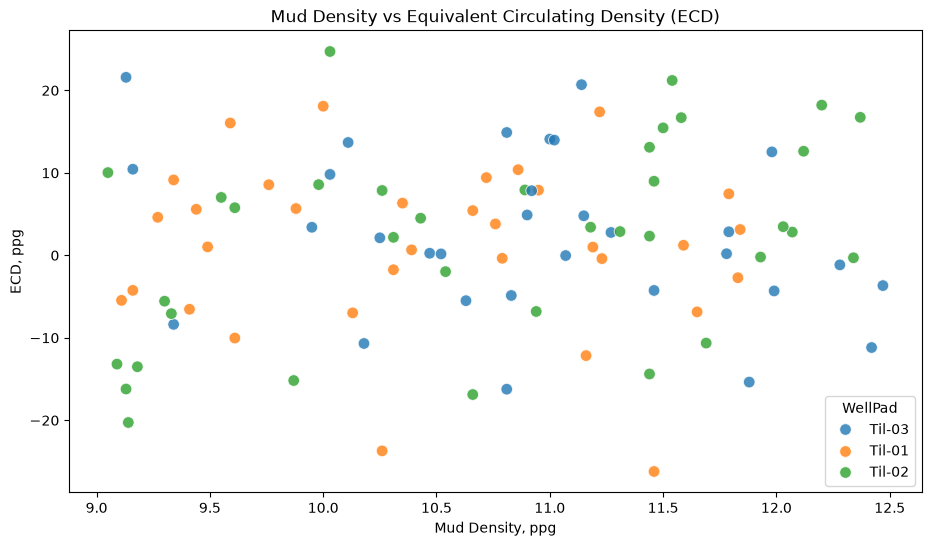

In [79]:
# 10 Mud Density vs ECD by Well Pad

plt.figure(figsize=(11, 6))
sns.scatterplot(data=df, x='Mud_Density_ppg', y='ECD_ppg',
                hue='WellPad', s=70, alpha=0.8)
plt.title('Mud Density vs Equivalent Circulating Density (ECD)')
plt.xlabel('Mud Density, ppg')
plt.ylabel('ECD, ppg')
plt.show()